# Altair — held-out cross-modal predictor (morphology ↔ expression)
**Question:** can a gene's **phase-imaging morphology** embedding predict its **scRNA-seq** embedding, *held-out*? Where it fails marks modality-specific biology. A clean public benchmark (CZ Biohub Altair atlas; 1,000 CRISPR KOs in A549).

**Design:** gene-level embeddings, 1000 shared genes. 5-fold **out-of-fold on held-out genes**, `StandardScaler` fit on train only (no leakage), multi-output `RidgeCV`. Metrics: held-out R², cross-modal **retrieval** (query one modality with the predicted embedding, rank the true gene among all 1000), and a **cross-validated CCA** (the leakage-free version of an in-sample CCA).

**Takeaways (computed below):**
- Phase morphology predicts ~**37–46%** of transcriptome-embedding variance out-of-fold; retrieves the true gene into the **top-10/1000 ~36%** of the time (chance 1%).
- Held-out CCA keeps **~4–5 strong shared axes** (top canonical r ≈ 0.95/0.92/0.83) — the shared structure is real, not overfit.
- Best cross-predicted: **ribosomal + COPI/secretory** genes. Worst: **cytoskeleton/actin, membrane trafficking, cell cycle** — where imaging carries orthogonal signal beyond transcriptomics.

In [1]:
import anndata as ad, numpy as np, pandas as pd, warnings
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cross_decomposition import CCA
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi":110,"font.size":10,"axes.spines.top":False,"axes.spines.right":False})
rng=np.random.default_rng(0); import os; os.makedirs("figures/prediction",exist_ok=True)

rna=ad.read_h5ad("data/cropseq_svaeplus_embedding_phate.h5ad")
img=ad.read_h5ad("data/ops_gene_embedding_phate_phase_only.h5ad")
rna_idx=rna.obs.index.astype(str); img_idx=img.obs["perturbation"].astype(str).values
CTRL={"control","nontargeting","non-targeting","NTC","safe"}
shared=[g for g in rna_idx if g in set(img_idx) and g not in CTRL]
rp={g:i for i,g in enumerate(rna_idx)}; ip={g:i for i,g in enumerate(img_idx)}
RNA=rna.obsm["X_sVAE"][[rp[g] for g in shared]].astype(float)
IMG=np.asarray(img.X)[[ip[g] for g in shared]].astype(float)
n=len(shared); alphas=np.logspace(-1,4,12)
print("shared genes:",n,"| RNA",RNA.shape,"| phase IMG",IMG.shape)

shared genes: 1000 | RNA (1000, 50) | phase IMG (1000, 97)


## 1. Held-out prediction (out-of-fold, per-fold scaling)

In [2]:
def oof_predict(X,Y):
    P=np.zeros_like(Y)
    for tr,te in KFold(5,shuffle=True,random_state=0).split(X):
        xs,ys=StandardScaler().fit(X[tr]),StandardScaler().fit(Y[tr])
        m=RidgeCV(alphas=alphas).fit(xs.transform(X[tr]),ys.transform(Y[tr]))
        P[te]=ys.inverse_transform(m.predict(xs.transform(X[te])))
    return P
def retrieval(pred,actual):
    S=cosine_similarity(pred,actual); order=np.argsort(-S,axis=1)
    ranks=np.array([np.where(order[i]==i)[0][0] for i in range(len(pred))])
    return dict(top1=np.mean(ranks==0),top5=np.mean(ranks<5),top10=np.mean(ranks<10),
               median_rank=float(np.median(ranks)+1)), ranks

res={}
for name,X,Y in [("morphology→RNA",IMG,RNA),("RNA→morphology",RNA,IMG)]:
    P=oof_predict(X,Y)
    met,ranks=retrieval(P,Y)
    res[name]=dict(r2u=r2_score(Y,P,multioutput="uniform_average"),
                   r2v=r2_score(Y,P,multioutput="variance_weighted"),**met,ranks=ranks)
    print(f"{name}: R2(unif)={res[name]['r2u']:.3f} R2(var-wt)={res[name]['r2v']:.3f} | "
          f"top1={met['top1']:.3f} top5={met['top5']:.3f} top10={met['top10']:.3f} med_rank={met['median_rank']:.0f}")
print(f"chance: top1={1/n:.4f} top5={5/n:.4f} top10={10/n:.4f} med_rank~{n//2}")

morphology→RNA: R2(unif)=0.366 R2(var-wt)=0.463 | top1=0.079 top5=0.257 top10=0.357 med_rank=29


RNA→morphology: R2(unif)=0.386 R2(var-wt)=0.416 | top1=0.044 top5=0.136 top10=0.199 med_rank=119
chance: top1=0.0010 top5=0.0050 top10=0.0100 med_rank~500


### Figure: held-out R² and cross-modal retrieval

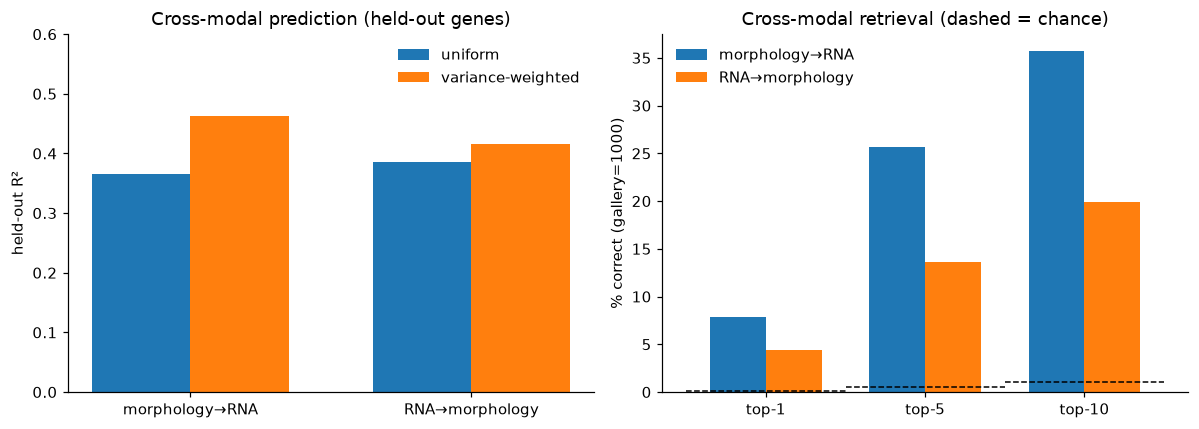

In [3]:
fig,ax=plt.subplots(1,2,figsize=(11,4))
dirs=list(res); x=np.arange(len(dirs)); w=0.35
ax[0].bar(x-w/2,[res[d]['r2u'] for d in dirs],w,label="uniform")
ax[0].bar(x+w/2,[res[d]['r2v'] for d in dirs],w,label="variance-weighted")
ax[0].set_xticks(x); ax[0].set_xticklabels(dirs); ax[0].set_ylabel("held-out R²")
ax[0].set_title("Cross-modal prediction (held-out genes)"); ax[0].legend(frameon=False); ax[0].set_ylim(0,0.6)
ks=["top1","top5","top10"]; xk=np.arange(len(ks))
for i,d in enumerate(dirs): ax[1].bar(xk+(i-0.5)*w,[res[d][k]*100 for k in ks],w,label=d)
for j,k in enumerate([1,5,10]): ax[1].plot([xk[j]-0.5,xk[j]+0.5],[k/n*100]*2,"k--",lw=1)
ax[1].set_xticks(xk); ax[1].set_xticklabels(["top-1","top-5","top-10"]); ax[1].set_ylabel("% correct (gallery=1000)")
ax[1].set_title("Cross-modal retrieval (dashed = chance)"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.savefig("figures/prediction/prediction_r2_retrieval.png",bbox_inches="tight",dpi=150); plt.show()

## 2. Cross-validated CCA — are the shared axes real?
In-sample CCA inflates. Here we fit CCA on train genes and measure canonical correlation on **held-out** genes, alongside the in-sample value for comparison.

held-out CCA: [0.951 0.831 0.919 0.834 0.679 0.71  0.761 0.677 0.644 0.544]
in-sample CCA: [0.977 0.955 0.951 0.932 0.898 0.887 0.874 0.86  0.841 0.829]


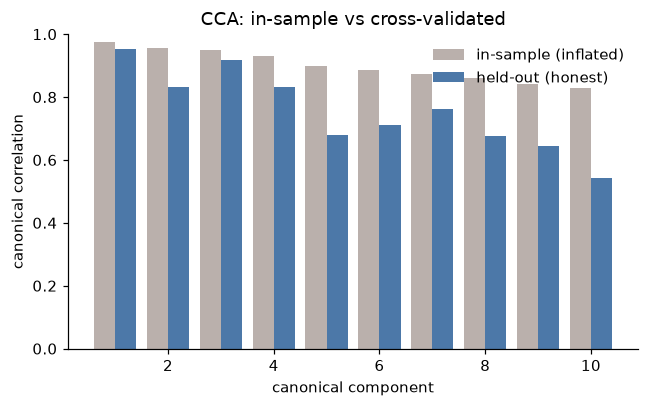

In [4]:
nc=10; test_cc=np.zeros((5,nc)); insample=[]
cca_all=CCA(n_components=nc,max_iter=2000)
Rs,Is=StandardScaler().fit_transform(RNA),StandardScaler().fit_transform(IMG)
a0,b0=cca_all.fit_transform(Rs,Is); insample=[np.corrcoef(a0[:,i],b0[:,i])[0,1] for i in range(nc)]
for f,(tr,te) in enumerate(KFold(5,shuffle=True,random_state=0).split(RNA)):
    xs,ys=StandardScaler().fit(RNA[tr]),StandardScaler().fit(IMG[tr])
    c=CCA(n_components=nc,max_iter=2000).fit(xs.transform(RNA[tr]),ys.transform(IMG[tr]))
    a,b=c.transform(xs.transform(RNA[te]),ys.transform(IMG[te]))
    test_cc[f]=[np.corrcoef(a[:,i],b[:,i])[0,1] for i in range(nc)]
hc=test_cc.mean(0)
print("held-out CCA:",np.round(hc,3)); print("in-sample CCA:",np.round(insample,3))
fig,ax=plt.subplots(figsize=(6,3.8)); xx=np.arange(1,nc+1)
ax.bar(xx-0.2,insample,0.4,label="in-sample (inflated)",color="#BAB0AC")
ax.bar(xx+0.2,hc,0.4,label="held-out (honest)",color="#4C78A8")
ax.set_xlabel("canonical component"); ax.set_ylabel("canonical correlation"); ax.set_ylim(0,1)
ax.set_title("CCA: in-sample vs cross-validated"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("figures/prediction/cca_cv.png",bbox_inches="tight",dpi=150); plt.show()

## 3. Where does morphology predict expression — and where not?
Per-gene held-out predictability = correlation between the morphology-predicted RNA embedding and the true RNA embedding. High = shared signal; low = modality-specific (imaging carries info the transcriptome doesn't reduce to).

best : ['RPS9', 'COPB1', 'RPS8', 'COPA', 'COPB2', 'RPS28', 'RPS3A', 'RPS5']
worst: ['DNAJA3', 'CHMP2A', 'ARPC4', 'ACTR3', 'ITGB1', 'TRAPPC2L', 'HGS', 'ZFR']


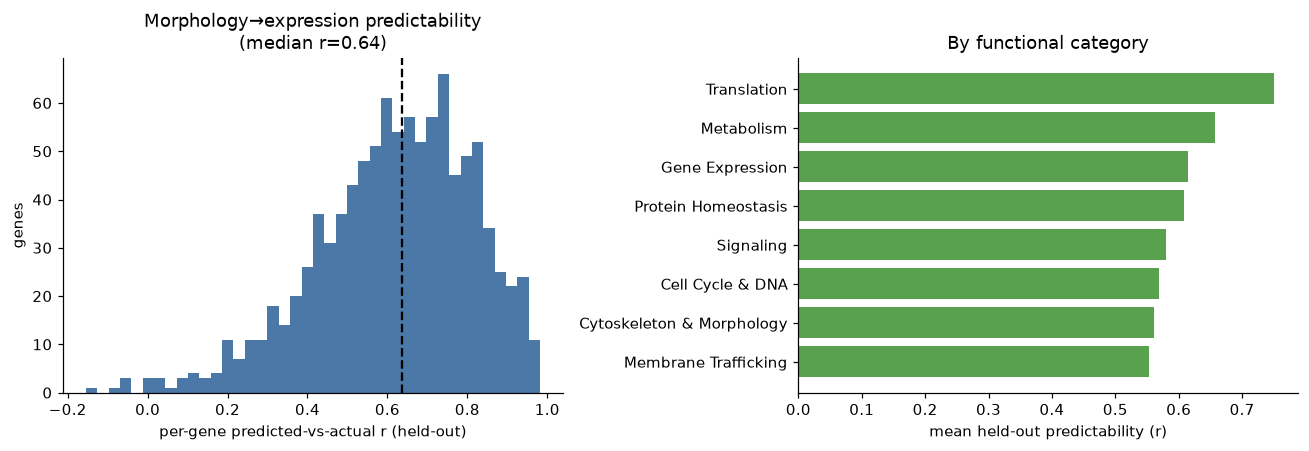

In [5]:
P=oof_predict(IMG,RNA)
pg=np.array([np.corrcoef(P[i],RNA[i])[0,1] for i in range(n)])
sc=img.obs.set_index("perturbation")["supercategory"].reindex(shared).astype(str).values
dfq=pd.DataFrame({"gene":shared,"pred_r":pg,"supercategory":sc})
dfq.to_csv("per_gene_predictability.csv",index=False)
print("best :",list(dfq.nlargest(8,'pred_r')['gene']))
print("worst:",list(dfq.nsmallest(8,'pred_r')['gene']))

keep=dfq[dfq.supercategory.isin([c for c,k in dfq.supercategory.value_counts().items() if k>=20 and c not in ('','nan')])]
mean_by=keep.groupby('supercategory')['pred_r'].mean().sort_values()
fig,ax=plt.subplots(1,2,figsize=(12,4.2))
ax[0].hist(pg,bins=40,color="#4C78A8"); ax[0].axvline(np.median(pg),color="k",ls="--")
ax[0].set_xlabel("per-gene predicted-vs-actual r (held-out)"); ax[0].set_ylabel("genes")
ax[0].set_title(f"Morphology→expression predictability\n(median r={np.median(pg):.2f})")
ax[1].barh(mean_by.index, mean_by.values, color="#59A14F")
ax[1].set_xlabel("mean held-out predictability (r)"); ax[1].set_title("By functional category")
plt.tight_layout(); plt.savefig("figures/prediction/per_gene_predictability.png",bbox_inches="tight",dpi=150); plt.show()

## 4. Takeaways & next steps
- **Morphology ⟺ expression is strongly, bidirectionally predictable at the gene level** — ~37–46% held-out R², retrieval ~20–37× above chance. Phase imaging (label-free, no stains) encodes a large, recoverable slice of the perturbation transcriptome.
- **Cross-validated CCA keeps ~4–5 axes at r≈0.8–0.95** — the shared structure survives honest evaluation.
- **The divergence is the interesting part:** ribosome/COPI/secretory genes are near-perfectly cross-predicted; **cytoskeleton/actin, membrane trafficking, and cell-cycle genes are the worst** — their morphological phenotype does not reduce to their transcriptome. That orthogonality is exactly why label-free imaging adds value beyond transcriptomics.

**Next:** (1) single-cell (not gene-level) cross-modal prediction; (2) fluorescence vs phase — which morphology aligns better with expression; (3) test whether these gene-function relationships transfer to other cell systems.

**Caveats:** gene-level pseudobulk embeddings; A549 only (single cell line); linear (ridge/CCA) predictors — a floor, not a ceiling.